In [1]:
import pandas as pd
import re

import os

In [2]:
# foreign launches
data_p_foreign = os.path.join(
    "..", "data", "raw",
    "foreign_launches.csv"
)

data_foreign = pd.read_csv(data_p_foreign)

# launches
data_p_all = os.path.join(
    "..", "data", "raw",
    "launches.csv"
)

data_all = pd.read_csv(data_p_all)


In [3]:
# foreign launches cleaning
df_f = data_foreign.copy()

df_f.head()

,Sl No ⇅,No. Name ⇅,Country,Date of Launch,Mass (Kg),Launch Vehicle
0,1,DLR-TUBSAT,GERMANY,26-May-99,45,PSLV-C2
1,2,KITSAT-3,REPUBLIC OF KOREA,26-May-99,110,PSLV-C2
2,3,BIRD,GERMANY,22-Oct-01,92,PSLV-C3
3,4,PROBA,BELGIUM,22-Oct-01,94,PSLV-C3
4,5,LAPAN-TUBSAT,INDONESIA,10-Jan-07,56,PSLV-C7


In [4]:
def num_launches(data):
    num = data.split("-")
    if len(num)>1:
        n1 = int(num[0])
        n2 = int(num[1])
        total = (n2 - n1 + 1)
    elif len(num)==1:
        total = 1
    else:
        total = 0

    return total

In [5]:
df_f["total_payloads"] = df_f["Sl No  ⇅"].apply(num_launches)

In [16]:
df_f.head(20)

,Sl No ⇅,No. Name ⇅,Country,Date of Launch,Mass (Kg),Launch Vehicle,total_payloads,Date
0,1,DLR-TUBSAT,GERMANY,26-May-99,45,PSLV-C2,1,1999-05-26
1,2,KITSAT-3,REPUBLIC OF KOREA,26-May-99,110,PSLV-C2,1,1999-05-26
2,3,BIRD,GERMANY,22-Oct-01,92,PSLV-C3,1,2001-10-22
3,4,PROBA,BELGIUM,22-Oct-01,94,PSLV-C3,1,2001-10-22
4,5,LAPAN-TUBSAT,INDONESIA,10-Jan-07,56,PSLV-C7,1,2007-01-10
5,6,PEHUENSAT-1,ARGENTINA,10-Jan-07,6,PSLV-C7,1,2007-01-10
6,7,AGILE,ITALY,23-Apr-07,350,PSLV-C8,1,2007-04-23
7,8,TECSAR,ISRAEL,21-Jan-08,300,PSLV-C10,1,2008-01-21
8,9,CAN-X2,CANADA,28-Apr-08,7,PSLV-C9,1,2008-04-28
9,10,CUTE-1.7,JAPAN,28-Apr-08,5,PSLV-C9,1,2008-04-28


In [17]:
df_f.columns

Index(['Sl No  ⇅', 'No. Name  ⇅', 'Country', 'Date of Launch', 'Mass (Kg)',
       'Launch Vehicle', 'total_payloads', 'Date'],
      dtype='str')

In [20]:
df_2 = df_f.drop(columns=['Sl No  ⇅', 'No. Name  ⇅', 'Date of Launch', 'Mass (Kg)'])

In [26]:
df_2.to_csv(
    os.path.join(
        "..", "data", "clean",
        "data_intermediary.csv"
    )
)

In [23]:
def build_payload_timeline(df):

    df = df.copy()

    # 1. Define country-to-region classification
    region_countries = {
        "USA": [
            "USA"
        ],

        "Europe": [
            "GERMANY",
            "BELGIUM",
            "ITALY",
            "THE NETHERLANDS",
            "NETHERLANDS",
            "DENMARK",
            "SWITZERLAND",
            "NORWAY",
            "LUXEMBOURG",
            "FRANCE",
            "AUSTRIA",
            "UNITED KINGDOM",
            "UK",
            "LATVIA",
            "FINLAND",
            "SLOVAKIA",
            "LITHUANIA",
            "CZECH REPUBLIC",
            "SPAIN",
            "ESA (WITH CONTRIBUTIONS FROM MULTIPLE EU COUNTRIES)"
        ],

        "Asia": [
            "REPUBLIC OF KOREA",
            "INDONESIA",
            "ISRAEL",
            "JAPAN",
            "TURKEY",
            "SINGAPORE",
            "KAZAKHSTAN",
            "UAE",
            "MALAYSIA"
        ],

        "Other": [
            "ARGENTINA",
            "CANADA",
            "ALGERIA",
            "CHILE",
            "AUSTRALIA",
            "COLOMBIA",
            "BRAZIL"
        ]
    }

    # 2. Build country-to-region mapping
    country_to_region = {
        country: region
        for region, countries in region_countries.items()
        for country in countries
    }

    # 3. Standardize country names
    df["country_clean"] = (
        df["Country"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    # 4. Assign regions
    df["region"] = df["country_clean"].map(country_to_region)

    # Check unmapped countries
    unmapped_countries = df.loc[
        df["region"].isna(),
        "Country"
    ].dropna().unique()

    if len(unmapped_countries) > 0:
        raise ValueError(
            f"Unmapped countries: {unmapped_countries.tolist()}"
        )

    # 5. Prepare date and payload columns
    df["Date"] = pd.to_datetime(df["Date"])

    df["total_payloads"] = pd.to_numeric(
        df["total_payloads"],
        errors="raise"
    )

    # 6. Aggregate payloads by date and region
    df_region = (
        df.groupby(["Date", "region"])["total_payloads"]
        .sum()
        .unstack(fill_value=0)
    )

    # Ensure all four regional columns exist
    regions = ["USA", "Europe", "Asia", "Other"]

    df_region = df_region.reindex(
        columns=regions,
        fill_value=0
    )

    # 7. Calculate daily total payloads
    df_region["total_payloads"] = df_region[regions].sum(axis=1)

    # 8. Sort chronologically
    df_region = df_region.sort_index()

    # 9. Calculate cumulative regional payload counts
    df_region[regions] = df_region[regions].cumsum()

    # 10. Calculate cumulative overall payload count
    df_region["Overall"] = df_region["total_payloads"].cumsum()

    # 11. Reset index and arrange columns
    df_final = df_region.reset_index()

    df_final = df_final[
        [
            "Date",
            "total_payloads",
            "Overall",
            "USA",
            "Europe",
            "Asia",
            "Other"
        ]
    ]

    return df_final

In [24]:
# df_f["Country"].value_counts()
df_f_country_total = df_f.groupby(
    by="Country",
    as_index=False
).agg(
    total_payloads=("total_payloads", "sum")
).sort_values(by="total_payloads", ascending=False)

In [25]:
# Define output directory
output_dir = os.path.join("..", "data", "clean")

# Create directory if it does not exist
os.makedirs(output_dir, exist_ok=True)

# Export CSV
df_f_country_total.to_csv(
    os.path.join(output_dir, "foreign_launches_total.csv"),
    index=False
)

In [14]:
# Define output directory
output_dir = os.path.join("..", "data", "clean")

# Create directory if it does not exist
os.makedirs(output_dir, exist_ok=True)

# Export CSV
df_f_date_total.to_csv(
    os.path.join(output_dir, "foreign_launches_datewise_cummulative.csv"),
    index=False
)

In [27]:
df_2.head()

,Country,Launch Vehicle,total_payloads,Date
0,GERMANY,PSLV-C2,1,1999-05-26
1,REPUBLIC OF KOREA,PSLV-C2,1,1999-05-26
2,GERMANY,PSLV-C3,1,2001-10-22
3,BELGIUM,PSLV-C3,1,2001-10-22
4,INDONESIA,PSLV-C7,1,2007-01-10


In [28]:
df_3 = build_payload_timeline(
    df=df_2
)

df_3.head(10)

region,Date,total_payloads,Overall,USA,Europe,Asia,Other
0,1999-05-26,2,2,0,1,1,0
1,2001-10-22,2,4,0,3,1,0
2,2007-01-10,2,6,0,3,2,1
3,2007-04-23,1,7,0,4,2,1
4,2008-01-21,1,8,0,4,3,1
5,2008-04-28,8,16,0,8,5,3
6,2009-09-23,6,22,0,13,6,3
7,2010-07-12,3,25,0,15,6,4
8,2011-04-20,1,26,0,15,7,4
9,2011-10-12,1,27,0,16,7,4


In [35]:
df_3.to_csv(
    os.path.join(
        "..", "data", "clean",
        "launches_clean_plotting.csv"
    ),
    index=False
)

<Axes: xlabel='Date'>

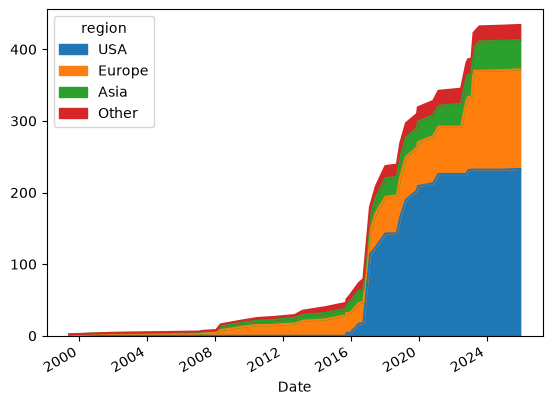

In [34]:
cols_plot = [
    "Date",
    "USA", "Europe", "Asia", "Other"
]

df_3[cols_plot].plot(
    x="Date",
    kind="area",
)